In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens

In [2]:
train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [3]:
print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


In [4]:
x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.5882
classification loss: 1.1909


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [6]:
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x: torch.Tensor):
        x = self.embedding(x)
        output, (h_n, c_n) = self.rnn(x)
        result = self.fc(output)

        return result

In [7]:
# Param setting
num_epochs = 100
vocab_size = train_data.vocab_size
context_size = 3 # 16, 32, 64, 128
embed_dim = 32
hidden_dim = 128
pad_id = 0
bos_id = 1
eos_id = 2

In [8]:
# LSTM training
model = LSTMModel(
    vocab_size = vocab_size,
    embed_dim = embed_dim,
    hidden_dim = hidden_dim
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train(model, train_loader, optimizer, device):
    model.train()
    total_loss = 0
    total_correct = 0

    for x, x_shifted, y, length in train_loader:
        x = x.to(device)
        x_shifted = x_shifted.to(device)

        # Forward
        outputs = model(x)

        B, L, V = outputs.shape
        targets = x_shifted.reshape(B * L)

        loss = F.cross_entropy(
            outputs.reshape(B * L, V),
            targets,
            ignore_index = -1
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # calculate loss and accuracy
        total_loss += loss.item()

        predictions = outputs.argmax(dim=-1)
        total_correct += (predictions == x_shifted).sum().item()

        avg_loss = total_loss / len(train_loader)
        avg_accuracy = total_correct / len(train_loader)

    return avg_loss, avg_accuracy

In [9]:
# LSTM validation
@torch.no_grad()
def validation(model, val_data, optimizer, device):
    model.eval()
    total_loss = 0
    total_correct = 0

    for x, x_shifted, y, length in train_loader:
        x = x.to(device)
        x_shifted = x_shifted.to(device)

        # Forward
        outputs = model(x)

        B, L, V = outputs.shape
        targets = x_shifted.reshape(B * L)

        loss = F.cross_entropy(
            outputs.reshape(B * L, V),
            targets,
            ignore_index = -1
        )

        # calculate loss and accuracy
        total_loss += loss.item()

        predictions = outputs.argmax(dim=-1)
        total_correct += (predictions == x_shifted).sum().item()

        avg_loss = total_loss / len(train_loader)
        avg_accuracy = total_correct / len(train_loader)

    return avg_loss, avg_accuracy

In [10]:
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}
rows = []

for epoch in range(num_epochs):
    train_loss, train_acc = train(model, train_loader, optimizer, device)
    val_loss, val_acc = validation(model, val_loader, optimizer, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # find the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1/100
Train Loss: 2.8491, Train Acc: 394.2315
Val Loss: 2.7319, Val Acc: 514.7525
Epoch 2/100
Train Loss: 2.6570, Train Acc: 595.9042
Val Loss: 2.5790, Val Acc: 666.0639
Epoch 3/100
Train Loss: 2.5108, Train Acc: 750.8782
Val Loss: 2.4486, Val Acc: 820.8822
Epoch 4/100
Train Loss: 2.3972, Train Acc: 878.9721
Val Loss: 2.3515, Val Acc: 929.6267
Epoch 5/100
Train Loss: 2.3174, Train Acc: 964.6766
Val Loss: 2.2842, Val Acc: 1004.0180
Epoch 6/100
Train Loss: 2.2558, Train Acc: 1031.2415
Val Loss: 2.2304, Val Acc: 1060.2116
Epoch 7/100
Train Loss: 2.2047, Train Acc: 1082.3473
Val Loss: 2.1832, Val Acc: 1099.8144
Epoch 8/100
Train Loss: 2.1625, Train Acc: 1121.2715
Val Loss: 2.1421, Val Acc: 1138.1637
Epoch 9/100
Train Loss: 2.1245, Train Acc: 1153.9441
Val Loss: 2.1080, Val Acc: 1173.0220
Epoch 10/100
Train Loss: 2.0897, Train Acc: 1184.9920
Val Loss: 2.0794, Val Acc: 1194.2754
Epoch 11/100
Train Loss: 2.0587, Train Acc: 1212.2156
Val Loss: 2.0434, Val Acc: 1228.1617
Epoch 12/100
Trai

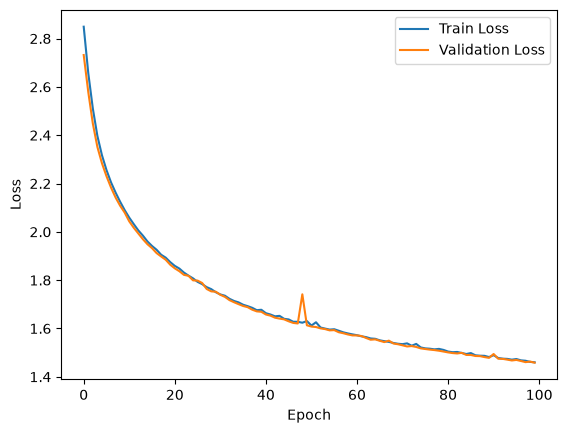

In [11]:
import matplotlib.pyplot as plt

plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()